![Banner](../images/03_02_banner_spatial_analysis_DTM.png)

# Digital Terrain Modeling (DTM)



Digital Terrain Modeling (DTM) is the process of representing, analyzing, and modeling the Earth's bare-ground surface using digital elevation data and computational techniques.

This notebook is the conceptual entry point for Module **03.02**. It defines DTM, separates DEM / DTM / DSM, summarises why terrain modeling matters (including for Bangladesh), and maps those ideas onto the GeoLattice APIs used in the two hands-on notebooks that follow.


Four notebooks take a DEM from a definition to streams and watersheds.

- **Digital Terrain Modeling (DTM).** This notebook. What a DTM is, how a DEM, a DTM, and a DSM differ, and why the bare-ground surface matters.
- **DEM Preprocessing.** Open the Bangladesh hilly-district DEM, read its metadata and elevation statistics, clip and resample it, and view it as a hillshade, a 3D surface, and a profile.
- **Terrain Derivatives and Morphometric Analysis.** Slope, aspect, hillshade, ruggedness, topographic position, roughness, curvature, wetness, landform class, viewshed, and contours.
- **Hydrology Modeling.** Breach and fill sinks, route flow, accumulate upslope area, extract streams, and delineate watersheds.

Libraries: `geolattice.spatial_analysis.terrain_analysis`, `geolattice.spatial_analysis.surface_hydrology`


## Table of Contents

- [What this chapter covers](#what-this-chapter-covers)
1. [What is Digital Terrain Modeling?](#what-is-digital-terrain-modeling)
2. [DEM, DTM, and DSM: What is the difference?](#dem-dtm-and-dsm-what-is-the-difference)
3. [Why is Digital Terrain Modeling important?](#why-is-digital-terrain-modeling-important)
4. [A typical DTM workflow](#a-typical-dtm-workflow)
5. [Digital Terrain Modeling with GeoLattice](#digital-terrain-modeling-with-geolattice)
6. [Quick-start: import and inspect a DEM](#quick-start-import-and-inspect-a-dem)
7. [Where to go next](#where-to-go-next)


## What is Digital Terrain Modeling?

**Digital Terrain Modeling (DTM)** represents, analyzes, and models the Earth's bare-ground surface from digital elevation data. A DTM captures three-dimensional topographic structure, including:

- Elevation and terrain morphology
- Slopes and slope directions (aspect)
- Ridges, valleys, hills, and depressions
- Surface curvature and terrain ruggedness
- Drainage patterns and potential water accumulation
- Visibility and other topographic relationships

DTM sits at the intersection of GIS, remote sensing, hydrology, geomorphology, environmental modeling, and spatial analysis. Elevation measurements become terrain attributes that support environmental monitoring, watershed management, flood modeling, agricultural planning, and infrastructure development.


## DEM, DTM, and DSM: What is the difference?

These three terms are closely related but describe different elevation surfaces.

### Digital Elevation Model (DEM)

A **DEM** is a raster of elevation values. Depending on the dataset and how it was produced, it may represent bare earth or include surface objects. In practice, many public "DEMs" (for example SRTM products) behave closer to a DSM in vegetated or built-up areas, so always check the product documentation.

### Digital Terrain Model (DTM)

A **DTM** represents the bare-earth terrain: buildings, trees, and other above-ground objects are removed. It is the preferred surface for geomorphological and hydrological analysis because flow and landform metrics should follow the ground, not rooftops or canopy.

### Digital Surface Model (DSM)

A **DSM** represents the uppermost surface elevation, including buildings, trees, and other above-ground features. DSMs are useful for viewsheds that include canopy or built form, urban canopy studies, and change detection of surface objects.

A simplified relationship is:

$$DSM \approx DTM + \text{above-ground object heights}$$

The equality is approximate. Vegetation penetration, building footprints, interpolation, sensor geometry, and processing choices all introduce differences between products.

| Surface | What it represents | Typical uses |
|---|---|---|
| **DEM** | Generic elevation raster (bare earth or mixed) | Broad elevation context; check metadata |
| **DTM** | Bare ground | Hydrology, landforms, geomorphometry |
| **DSM** | Ground + above-ground objects | Urban canopy, line-of-sight with obstacles |


## Why is Digital Terrain Modeling important?

| Application | Example |
|---|---|
| Hydrology | Watershed delineation and drainage modeling |
| Flood modeling | Flood-prone area identification |
| Agriculture | Land suitability and irrigation planning |
| Geomorphology | Ridge, valley, and landform identification |
| Environmental science | Soil erosion and sediment transport |
| Infrastructure | Road and railway route planning |
| Ecology | Habitat suitability and landscape connectivity |
| Disaster management | Landslide susceptibility and flood risk |

For Bangladesh, DTM analysis is especially useful for floodplain topography, river channels, coastal chars, seasonal inundation, drainage patterns, and agricultural land suitability. Low-relief floodplains and dense drainage networks reward careful DEM conditioning before flow routing; steeper hill tracts reward morphometric derivatives such as slope, TPI, and landform class.


## A typical DTM workflow

Most terrain and hydrology studies follow the same sequence, whether the study area is a Bangladesh upazila or a mountain catchment:

1. **Acquire elevation data.** Choose a DEM / DTM with a resolution and vertical accuracy that match the question (for example 30-90 m SRTM-class products for regional work; finer lidar DTMs for local engineering).
2. **Reproject and clip.** Work in a metric CRS so slope, distance, and accumulation have meaningful units. Clip to the area of interest to keep later steps responsive.
3. **Inspect the surface.** Plot elevation and hillshade; check nodata, voids, and vertical units.
4. **Derive morphometric attributes.** Slope, aspect, curvature, TRI / TPI / roughness, landforms, viewshed, and contours describe form and relative position.
5. **Condition the DEM for hydrology.** Breach or fill depressions so water can drain (covered in the hydrology notebook).
6. **Route flow and extract networks.** Flow direction, accumulation, streams, and watersheds turn elevation into drainage structure.
7. **Compute terrain-hydrology indices.** TWI, elevation above stream, and related indices connect form to wetness and floodplain context.

GeoLattice splits steps 4 and 5-7 across `terrain_analysis` and `surface_hydrology` so each notebook stays focused.


## Digital Terrain Modeling with GeoLattice

GeoLattice exposes DTM work through two modules under `geolattice.spatial_analysis`:

| Module | Role | Hands-on notebook |
|---|---|---|
| `terrain_analysis` | Morphometric derivatives and cartographic relief from a DEM | [03_02_02_terrain_analysis.ipynb](03_02_02_terrain_analysis.ipynb) |
| `surface_hydrology` | DEM conditioning, flow routing, streams, watersheds, wetness / floodplain indices | [03_02_03_hydrology_modeling.ipynb](03_02_03_hydrology_modeling.ipynb) |

Both notebooks use the Bangladesh hilly-district DEM at `Data/00_shared/raster_data/Bangladesh/hilly_dem_BTM.tiff` (Bangladesh Transverse Mercator, 250 m SRTM-class surface).

### `terrain_analysis` products

| Product | What it measures | Backend notes |
|---|---|---|
| `slope`, `aspect` | Steepness; downhill direction from north | GDAL `gdaldem` |
| `hillshade` | Shaded relief (single or multidirectional) | GDAL `gdaldem` |
| `tri`, `tpi`, `roughness` | Local ruggedness and relative position | GDAL `gdaldem` / windowed NumPy |
| `curvature` family | Mean, profile, plan, tangential, Gaussian | NumPy (Zevenbergen-style) |
| `twi` | Topographic wetness from upslope area and slope | NumPy |
| `landform_classification` | Weiss-style classes from nested TPI | NumPy |
| `multiscale_analysis` | Metric across odd window sizes | NumPy |
| `viewshed` | Line-of-sight from observer(s) | NumPy |
| `contours` | Vector elevation lines | GDAL contour |

### `surface_hydrology` products

| Stage | Functions | Role |
|---|---|---|
| DEM conditioning | `breach_depressions`, `fill_depressions` | Remove sinks so flow can drain |
| Flow direction | `d8_pointer`, `rho8_pointer`, `dinf_pointer`, `fd8_pointer`, ... | Encode where water leaves each cell |
| Flow accumulation | `d8_flow_accumulation`, `dinf_flow_accumulation` | Upslope area / SCA |
| Streams | `extract_streams`, `stream_segmentation` | Threshold and label the channel network |
| Watersheds | `watershed`, `subbasins`, `basins`, `snap_pour_points` | Upslope catchments |
| Indices | `twi`, `elevation_above_stream`, `downslope_distance_to_stream` | Wetness and floodplain proxies |
| Advanced | `stochastic_depression_analysis`, `hydrologic_connectivity`, `impoundment_analysis` | Uncertainty and storage |

### Import pattern

```python
import geolattice.spatial_analysis.terrain_analysis as ta
import geolattice.spatial_analysis.surface_hydrology as sh

# Or import named tools from the package facade:
from geolattice.spatial_analysis import slope, aspect, hillshade, breach_depressions, d8_pointer
```

The next cell resolves the repository root the same way as the hands-on notebooks, imports both APIs, and opens the sample DEM for a short metadata check and hillshade preview.


## Quick-start: import and inspect a DEM

Locate the repository root, import the DTM modules, summarise the Bangladesh DEM, and draw a quick elevation / hillshade pair so the surface is tangible before the deeper notebooks.


**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

from pathlib import Path  # filesystem paths for locating the DEM

# Third-party plotting stack.S
import matplotlib.pyplot as plt  # figure and axes for the DEM preview

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Raster helpers and terrain / hydrology APIs (expects an installed / editable geolattice).
from geolattice.raster import open_raster_data, summarize_raster  # DEM metadata and stats
from geolattice.spatial_analysis import hillshade  # shaded relief for the preview map
import geolattice.spatial_analysis.terrain_analysis as ta  # morphometric API
import geolattice.spatial_analysis.surface_hydrology as sh  # hydrologic API
from geolattice.viz import apply_map_style, plot_raster  # tutorial map styling

apply_map_style()  # apply the GeoLattice tutorial matplotlib map defaults

# Sample DEM used throughout 03.02.
DEM = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh" / "hilly_dem_BTM.tiff"
assert DEM.exists(), f"Missing DEM: {DEM}"

OUT = ROOT / "Data" / "00_shared" / "raster_data" / "output_folder" / "bangladesh" / "dtm_intro"
OUT.mkdir(parents=True, exist_ok=True)

print(f"ROOT:              {ROOT}")
print(f"DEM:               {DEM}")
print(f"terrain_analysis:  {ta.__file__}")
print(f"surface_hydrology: {sh.__file__}")
print(f"terrain tools:     {len(ta.__all__)}")
print(f"hydrology tools:   {len(sh.__all__)}")


ROOT:              /home/zia207/Github/GeoLattice
DEM:               /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh/hilly_dem_BTM.tiff
terrain_analysis:  /tmp/geolattice-src-path/geolattice/spatial_analysis/terrain_analysis.py
surface_hydrology: /tmp/geolattice-src-path/geolattice/spatial_analysis/surface_hydrology.py
terrain tools:     19
hydrology tools:   30


In [2]:
# Print DEM metadata and a short elevation summary.
with open_raster_data(DEM) as ds:
    gt = ds.geotransform
    print(f"size:    {ds.width} x {ds.height}  bands={ds.band_count}")
    print(f"res:     {abs(gt[1]):.4f} x {abs(gt[5]):.4f}")
    print(f"bounds:  {ds.bounds}")
    print(f"crs:     {ds.crs}")
    print(f"nodata:  {ds.get_band(1).nodata}")

summary = summarize_raster(DEM)
print(summary)


size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan
{'count': 310665, 'min': -7.79642915725708, 'max': 985.0496215820312, 'mean': 109.00788921668955, 'std': 129.04998617063526, 'sum': 33864935.90350286, 'percentiles': {'p2': 3.0354053211212157, 'p98': 544.4429467773432}}


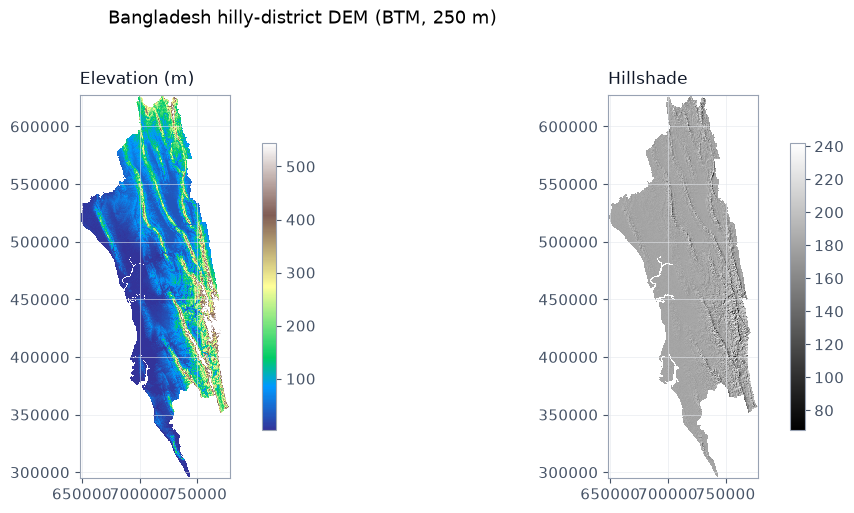

In [3]:
# Build a hillshade beside the DEM so relief is easier to read.
hs_path = OUT / "intro_hillshade.tif"
hillshade(DEM, hs_path, overwrite=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_raster(DEM, ax=axes[0], title="Elevation (m)", cmap="terrain", robust=True, show=False)
plot_raster(hs_path, ax=axes[1], title="Hillshade", cmap="gray", show=False)
fig.suptitle("Bangladesh hilly-district DEM (BTM, 250 m)", y=1.02)
fig.tight_layout()
plt.show()


## Where to go next

1. Continue with [Terrain Derivatives and Morphometric Analysis](03_02_02_terrain_analysis.ipynb) for slope, aspect, ruggedness, curvature, landforms, viewshed, and contours.
2. Then open [Hydrology Modeling](03_02_03_hydrology_modeling.ipynb) for depression handling, flow routing, stream extraction, watersheds, and terrain-hydrology indices.

Both notebooks reuse the same DEM path and the same repository-root setup pattern shown above. Suitability work that consumes terrain layers (for example slope as a siting criterion) continues later in Module 03.05 (MCSM).
